# Import the libraries

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

# Data

## Import

In [80]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"

df = pd.read_csv(url)

display(df.head()) #shows the first 5 raws of the dataframe

print("Numero di righe:", len(df)) #prints the number of rows in the dataframe

print("Nomi delle colonne:", df.columns.tolist()) #prints the names of the columns in the dataframe

,observation_date,SP500
0,2016-10-17,2126.50
1,2016-10-18,2139.60
2,2016-10-19,2144.29
3,2016-10-20,2141.34
4,2016-10-21,2141.16


Numero di righe: 2610
Nomi delle colonne: ['observation_date', 'SP500']


## Cleaning the data

The market is not always open, for example it closes during weekends and holidays. The $S
\&P500$ index is marked in the dataset as a NaN value.

In [81]:
print("\nWe have ", len( df[df['observation_date'].isna()]), "NaN values in the observation_date column")
print("\nWe have ", len( df[df['SP500'].isna()]), "NaN values in the SP500 column") #prints the number of NaN values in the SP500 column


We have  0 NaN values in the observation_date column

We have  96 NaN values in the SP500 column


In [82]:
print(df.dtypes)

# Convert the observation_date column to datetime format
df["observation_date"] = pd.to_datetime(df["observation_date"]) 
print("\nObserve the type of the column is not str anymore:")
print(df.dtypes) 

# Remove rows containing missing values
prices = df.dropna()
print("\nNew shape after removing NaN values:", prices.shape)

# Sort observations chronologically
prices = prices.sort_values("observation_date").reset_index(drop=True)

# Rename the date column
prices = prices.rename(columns={"observation_date": "Date"})
print("Now the name of the columns is", prices.columns.to_list())


print("Original observations:", len(df))
print("Valid observations:", len(prices))

display(prices.head())
display(prices.tail())


observation_date        str
SP500               float64
dtype: object

Observe the type of the column is not str anymore:
observation_date    datetime64[us]
SP500                      float64
dtype: object

New shape after removing NaN values: (2514, 2)
Now the name of the columns is ['Date', 'SP500']
Original observations: 2610
Valid observations: 2514


,Date,SP500
0,2016-10-17,2126.50
1,2016-10-18,2139.60
2,2016-10-19,2144.29
3,2016-10-20,2141.34
4,2016-10-21,2141.16


,Date,SP500
2509,2026-10-12,7807.24
2510,2026-10-13,7805.45
2511,2026-10-14,7718.94
2512,2026-10-15,7744.06
2513,2026-10-16,7659.44


## Plotting the data

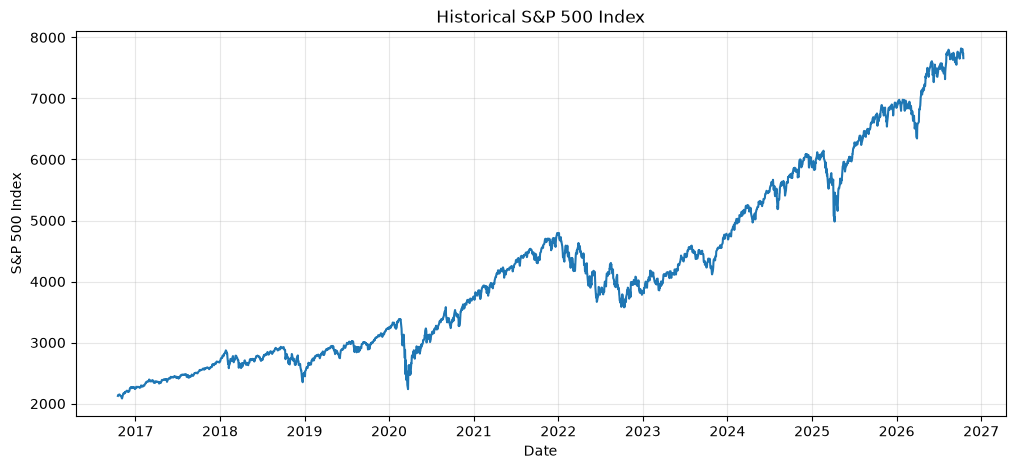

In [83]:
plt.figure(figsize=(12, 5))

plt.plot(prices["Date"], prices["SP500"])

plt.xlabel("Date")
plt.ylabel("S&P 500 Index")
plt.title("Historical S&P 500 Index")

plt.grid(alpha=0.3)
plt.show()

# Logarithmic returns distribution analisys

## Compute the logarithmic returns

In this work, we are interested in the distribution of the logarithmic returns $r_t$, defined as

$$
r_t \equiv \ln\left(\frac{P_t}{P_{t-1}}\right).
$$


In [84]:
#create a new dataframe for return analisys

returns_df = prices.copy() 
returns_df.columns.to_list()
returns_df["Returns"] = np.log(returns_df["SP500"]/returns_df["SP500"].shift(1))
returns_df = returns_df.dropna()

print(returns_df.head())
print(returns_df.tail())

        Date    SP500   Returns
1 2016-10-18  2139.60  0.006141
2 2016-10-19  2144.29  0.002190
3 2016-10-20  2141.34 -0.001377
4 2016-10-21  2141.16 -0.000084
5 2016-10-24  2151.33  0.004739
           Date    SP500   Returns
2509 2026-10-12  7807.24 -0.000551
2510 2026-10-13  7805.45 -0.000229
2511 2026-10-14  7718.94 -0.011145
2512 2026-10-15  7744.06  0.003249
2513 2026-10-16  7659.44 -0.010987


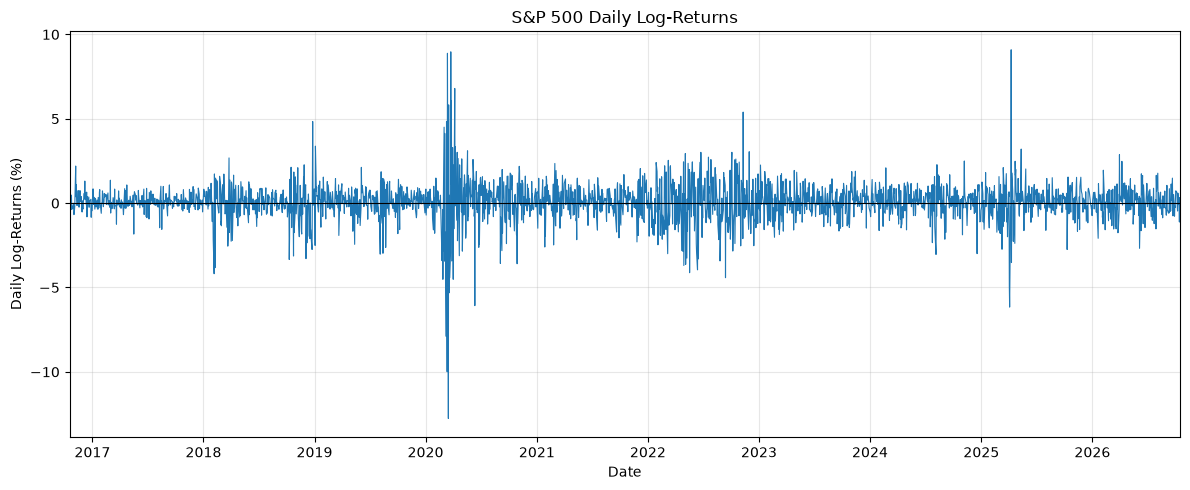

count    2513.000000
mean        0.000510
std         0.011413
min        -0.127652
25%        -0.003764
50%         0.000767
75%         0.005876
max         0.090895
Name: Returns, dtype: float64

In [85]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(returns_df["Date"], 100 * returns_df["Returns"], linewidth=0.8)

ax.axhline(0, color="black", linewidth=0.8)

# Make the plot start and end exactly at the first and last observations
ax.set_xlim(returns_df["Date"].min(), returns_df["Date"].max())

ax.set_xlabel("Date")
ax.set_ylabel("Daily Log-Returns (%)")
ax.set_title("S&P 500 Daily Log-Returns")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

returns_df["Returns"].describe()

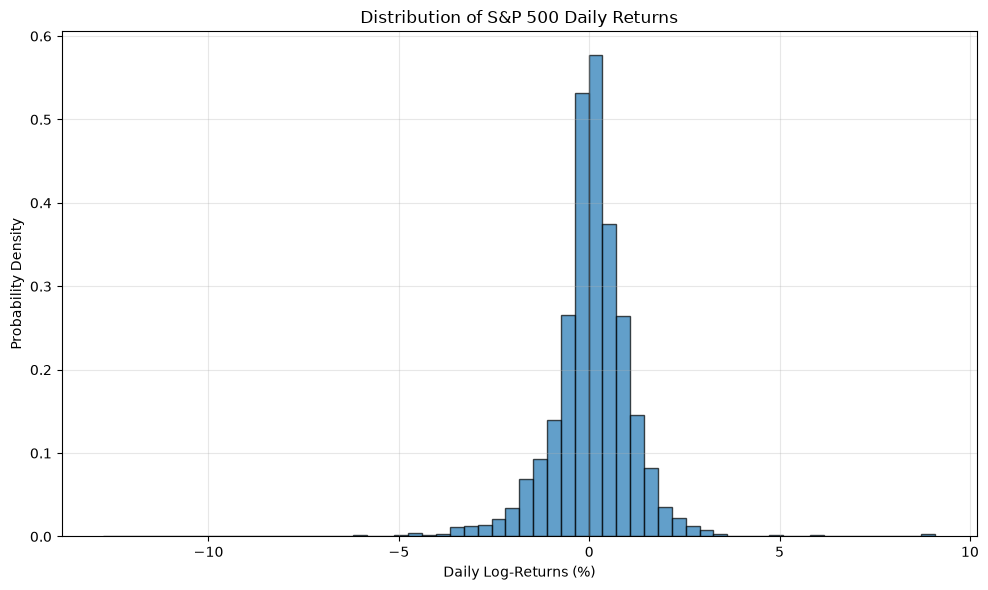

In [86]:
# Daily log-returns expressed as percentages
r = 100 * returns_df["Returns"]

# Histogram
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(r, bins=60, density=True, edgecolor="black", alpha=0.7)

ax.set_xlabel("Daily Log-Returns (%)")
ax.set_ylabel("Probability Density")
ax.set_title("Distribution of S&P 500 Daily Returns")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Warmp up: is the $r_t$ distribution Gaussian?

In this section we begin the statistical analisys the $r_t$ distribution. In particular, we consider a measurement of the logarithmic return $r_t$ as the istance of a random variable, distributed according an unknown Probability Density Function (PDF)

$$

r_t \sim p(\dots).

$$
we begin by the empirical distribution PDF for $r_t$. 

#### Naive superposition

In [87]:
mu_hat = r.mean()
sigma_hat = r.std() 
print("The estimated mean is", mu_hat)
print("The estimated standard dev", sigma_hat)

The estimated mean is 0.05099329241221205
The estimated standard dev 1.1413481013707685


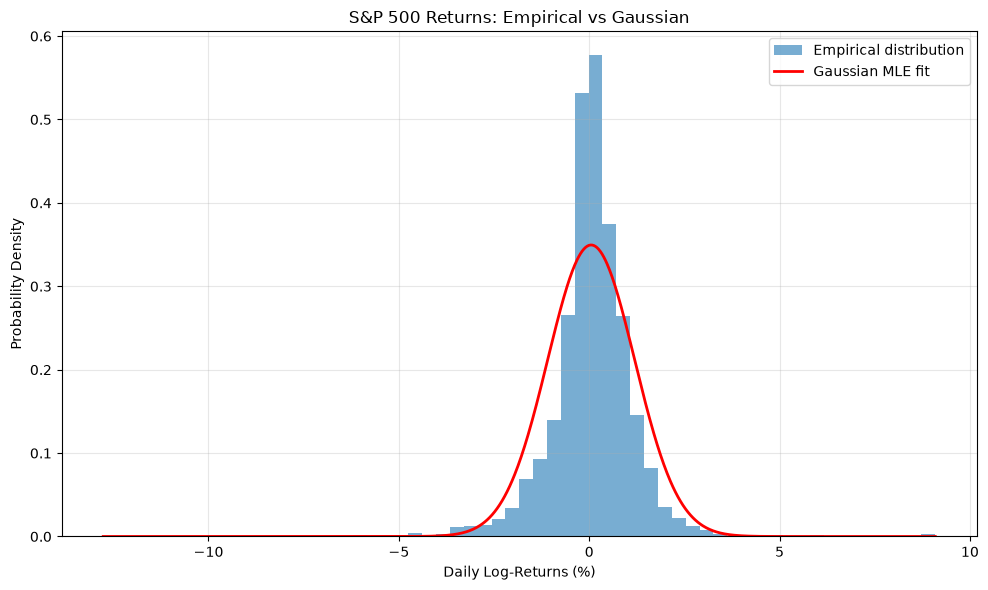

In [88]:
# Generate points for the theoretical Gaussian curve
x = np.linspace(r.min(), r.max(), 1000)

# Evaluate Gaussian probability density
gaussian_pdf = norm.pdf(x, loc=mu_hat, scale=sigma_hat)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

# Empirical distribution
counts, binhedge, patches =  ax.hist(
    r,
    bins=60,
    density=True,
    alpha=0.6,
    label="Empirical distribution"
)


# Gaussian model
ax.plot(
    x,
    gaussian_pdf,
    color="red",
    linewidth=2,
    label="Gaussian MLE fit"
)

ax.set_xlabel("Daily Log-Returns (%)")
ax.set_ylabel("Probability Density")
ax.set_title("S&P 500 Returns: Empirical vs Gaussian")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Goodness-of-fit test with Pearson Chi2

What we want to do here is to understand wether the observed data is compatible with the hypotesys  

$$

H_0: r_i \sim \mathcal{N}(\mu,\sigma^2).

$$



The first we have to in order to set a Pearson-$\chi^2$ test is to choose the binning. We want the expected frequency in each bin to be sufficiently large for to assume that the number of observed data in each bin follows a Poisson distribution. Therefore, we divide the interval $\{-\infty,\infty\}$ in $B = 20$ bins such that

Therefore, we divide the interval $(-\infty,\infty)$ in $B = 20$ bins such that

$$
P(r_i \in I_a) = p, \qquad a = 1,\dots,B, \tag{1}
$$
with $p= 1/B = 0.05$, and  $I_a$ denoting the intervals of the binning.

Such intervals are determined as follows. First of all we introduce the notation for the edges of the intervals that define the binning: 

$$

I_a = (b_a, b_{n+1}).

$$

Now we notice that Eq.(1) can be rewritten as 

$$

F_{H_0}(b_i) = \frac{(i-1)}{B},

$$

with $F_{H_0}$ the cumulative under the null hypothesis $H_0$. 

The intervals are thus found as 

$$

b_i = F_{H_0}^{-1}\biggl(\frac{i-1}{B}\biggr).

$$




In [89]:
# Daily log-returns in percentage
r = r.to_numpy()

In [90]:
B = 20 
p = np.arange(B+1)/B

b = norm.ppf(p, mu_hat, sigma_hat  ) # inverse cumulative of a gaussian

print("Number of edges:",len(b))
print("First few edges:",b[0:5])


Number of edges: 21
First few edges: [       -inf -1.82635727 -1.41170315 -1.13193799 -0.9095895 ]


In [91]:
# rebinning:
O, _ = np.histogram(r, bins=b)

print("Observed counts:", O)
print("Total observations:", O.sum())

N = len(r)

E = N / B

print("\nExpected counts per bin:", E)


X2_obs = np.sum((O-E)**2/E)

print("\nObserved Pearson Chi2:", X2_obs)



Observed counts: [105  72  62  61  97 107 109 161 208 235 234 175 163 147 140 109 117  77
  65  69]
Total observations: 2513

Expected counts per bin: 125.65

Observed Pearson Chi2: 468.0346199761241


Normally, in order to interpret this results, one might be tempted to rely on the asymptotic chi-square distribution of the Pearson's test statistic and use it to compute the probability of obtaining a value greater that the one observed. However, we estimated the parameters $\hat \mu$ and $\hat \sigma$ using the observed data, meaning that our bin boundaries also depend on the observed sample. 

In order to understand the consequences of this fact, consider the simple example in which we have only two observations $r_1$ and $r_2$. Now we build the bin using the average 

$$

\hat \mu = \frac{1}{2}(r_1 +r_2).

$$

we can assume WLG that $r_1 < \hat \mu < r_2$, denoting with $O_i$ the observed number of  observations in the bin $i$, we then have

$$

(O_1,O_2) = (1,1).

$$

However, using the true unknown average, we might have found 

$$

(O_1,O_2) = (2,0),(1,1),(0,2).

$$

This means that estimating the parameters from the data we have modified the possible fluctuations of the observed number of observations in each bin. As a consequence, the asymptotic distribution of the Pearson's chi-square is no longer necessarilty the one predicted by the asymptotic theorem. 

For this reason, we perform a parametric bootstrap in order to numerically build the distribution of the test statitics. 
In the following, we explain how this works. 

We begin by generating a sample of $N = 2512 $ data under the hypothesis $H_0$:

$$

r_t^{*} \sim \mathcal{N}(\hat \mu, \hat \sigma),

$$

and estimate again the paramters

$$

\hat \mu^{*} = \frac1N \sum_{t^1}^N r_t^{*}, \quad (\hat \sigma^{*})^2 = \frac{1}{N-1}\sum_{t= 1}^{N} (r_t- \hat \mu^*)^2. 

$$

Now we compute again the Pearson chi-square 

$$

\chi^{2\, *}_{pearson} = \sum_{a=1}^{N}\frac{(O_a^{*} - N/B)^2}{N/B}.

$$


We now generate $n = 5000$ samples under the null hypothesis, then we re-estimate the parameters and compute the  pearson chi-square for each of the $n$ samples.  

In [92]:
n = 5000
rstar = []
l = []
i = 0 
while i < n:
    rnew = np.random.normal(mu_hat,sigma_hat,size=len(r))
    rstar.append(rnew)
    l.append([rnew.mean(),rnew.std()])
    i+=1

l = np.array(l)
rstar = np.array(rstar)

bstar  = norm.ppf(p,l[:,0,None], l[:,1,None])

Ostar = []
i = 0
while i < n:
    Onew,_ = np.histogram(rstar[i], bins=bstar[i,:])
    Ostar.append(Onew)
    i+=1

Ostar = np.array(Ostar)
print(Ostar.shape)


X2star = np.sum((Ostar- E)**2/E,axis=1)

X2star.shape


(5000, 20)


(5000,)

Now we plot the histogram of the n estractions of the Pearson chi-square

<function matplotlib.pyplot.show(close=None, block=None)>

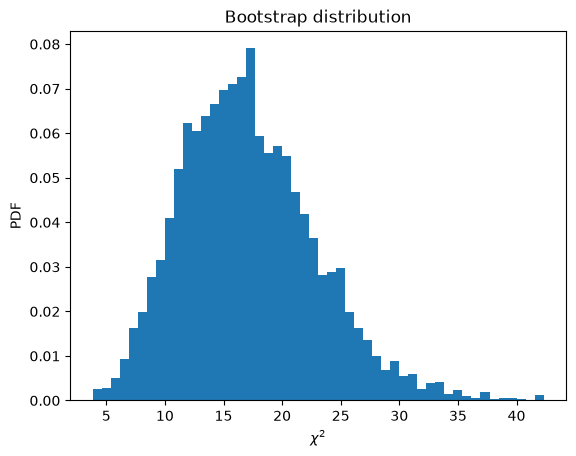

In [93]:
plt.hist(X2star, bins = 50, density=True)

plt.xlabel(r'$\chi^2$')
plt.ylabel('PDF')
plt.title('Bootstrap distribution')

plt.show

In [102]:
K = np.sum(X2star >= X2_obs)
pvalue = (K+1)/(n+1)
print("p-value is", pvalue) 

p-value is 0.0001999600079984003
